# Cartagena 3: asfalto y vegetacion con longitud de arco

Importamos librerías

In [1]:
from spectral import *
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import cv2
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

Cargamos la imagen

In [2]:
ruta="../datos/cartagena3"
img=open_image(ruta+"/imagen/cartagena3.hdr")
arr=np.asarray(img.load())
arr.shape

(750, 750, 380)

Normalizamos el arreglo con la imagen

In [3]:
maximo=np.max(arr)
minimo=np.min(arr)
arr_norm=(arr-minimo)/(maximo-minimo)

Marcamos los píxeles que sí tienen datos. Las zonas negras de la imagen están en cero en todas las bandas y no se deben usar ni pintar

In [4]:
con_datos=np.max(arr,axis=2)>0
print("Píxeles sin datos:", np.sum(~con_datos))

Píxeles sin datos: 409


Imagen base para dibujar

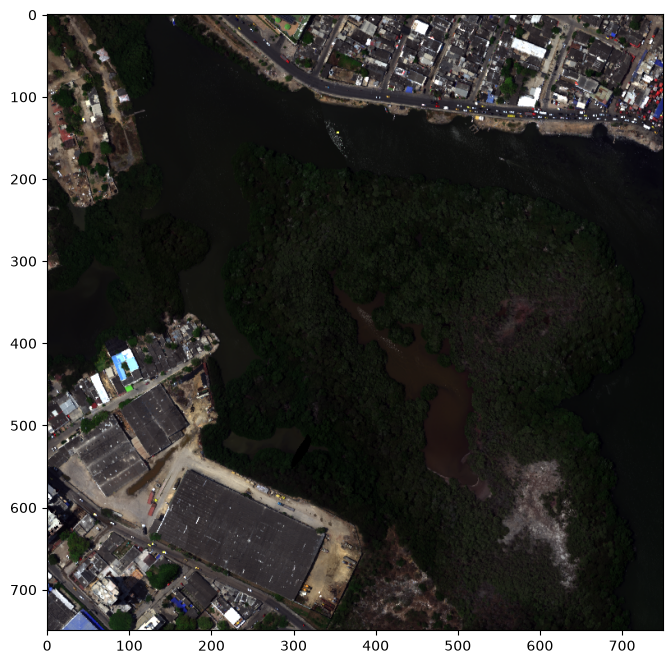

In [5]:
imagen=cv2.cvtColor(cv2.imread(ruta+"/imagen/cartagena3.png"), cv2.COLOR_BGR2RGB)
plt.figure(figsize=(8, 8))
plt.imshow(imagen)
plt.show()

Definimos la función de longitud de arco y el método de similitud (iguales al original)

In [6]:
def long_arco(R):
  return np.sum(np.abs(np.diff(R)))

def similitud_porcentual(A, B):
  A, B = np.array(A), np.array(B)
  #Similitud por posición: 100 si iguales, 0 si muy distintos
  sims = 100 * (1 - np.abs(A - B) / (np.abs(A) + np.abs(B) + 1e-9))
  return np.mean(sims)

# Muestras de los materiales
Las zonas de cada material se marcan en ImageJ y se guardan en `datos/cartagenaN/muestras/` (ver el README).
Las pasamos a recuadros (x1, y1, x2, y2). Cada material se compara contra **los demás materiales** de la imagen.

In [7]:
def leer_imagej(archivo):
  m=pd.read_csv(archivo)
  if "x" in m.columns:
    #Un píxel por fila (x, y): cada píxel es un recuadro de 1x1
    return pd.DataFrame({"x1":m.x, "y1":m.y, "x2":m.x+1, "y2":m.y+1}).round().astype(int)
  #Un rectángulo por fila: ImageJ guarda la esquina de arriba a la izquierda (BX, BY) y el tamaño (Width, Height)
  return pd.DataFrame({"x1":m.BX, "y1":m.BY, "x2":m.BX+m.Width, "y2":m.BY+m.Height}).round().astype(int)

recuadros={}
recuadros["asfalto"]=leer_imagej(ruta+"/muestras/asfalto.csv")
recuadros["vegetacion"]=leer_imagej(ruta+"/muestras/vegetacion.csv")
for nombre in recuadros:
  print(nombre, ":", len(recuadros[nombre]), "recuadros")

asfalto : 190 recuadros
vegetacion : 381 recuadros


Dibujamos las muestras de cada material con su color

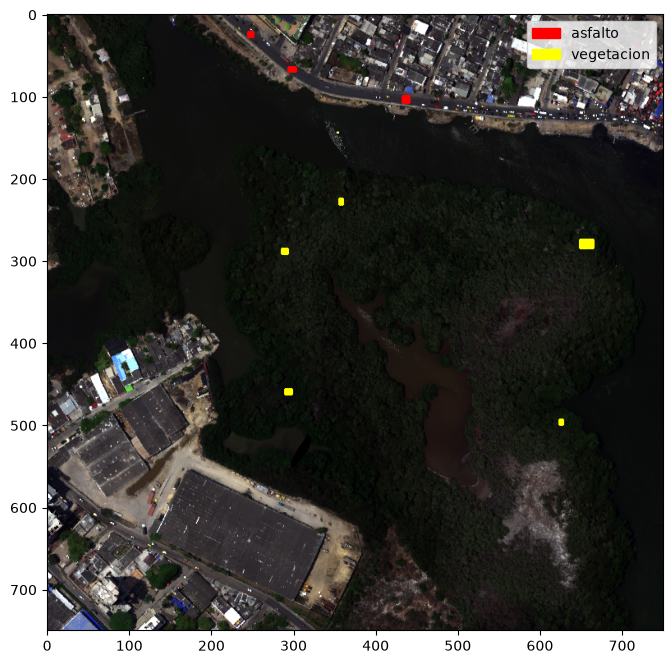

In [8]:
colores={"asfalto":(255, 0, 0), "vegetacion":(255, 255, 0)}
img_copy=imagen.copy()
for nombre in recuadros:
  for id,r in recuadros[nombre].iterrows():
    cv2.rectangle(img_copy, (r.x1,r.y1), (r.x2-1,r.y2-1), colores[nombre], 2)
plt.figure(figsize=(8, 8))
plt.imshow(img_copy)
plt.legend(handles=[mpatches.Patch(color=np.array(colores[m])/255, label=m.replace("_"," ")) for m in colores], loc="upper right")
plt.show()

Función para sacar los píxeles (con datos) que hay dentro de unos recuadros

In [9]:
def pixeles_de(rec):
  l_pix=[]
  for id,r in rec.iterrows():
    for y in range(r.y1,r.y2):
      for x in range(r.x1,r.x2):
        if(con_datos[y][x]):
          l_pix.append((x,y))
  return pd.DataFrame(l_pix, columns=["x","y"])

In [10]:
#Aquí se guardan los mapas de similitud y umbrales de cada material
mapas={}
umbrales={}

# Material 1: asfalto

Sacamos los píxeles de los recuadros: asfalto (si) y los demás materiales (no). Tomamos 250 de cada uno al azar, como en el original

In [11]:
df_si=pixeles_de(recuadros["asfalto"])
df_no=pixeles_de(pd.concat([recuadros[m] for m in recuadros if m!="asfalto"]))
print("Píxeles de asfalto:", len(df_si), " otros:", len(df_no))
df_si=df_si.sample(n=min(250,len(df_si)),random_state=42)
df_no=df_no.sample(n=min(250,len(df_no)),random_state=42)
punt_si=df_si[["x","y"]].astype(int).to_numpy()
punt_no=df_no[["x","y"]].astype(int).to_numpy()
print("Usados:", len(punt_si), len(punt_no))

Píxeles de asfalto: 190  otros: 381
Usados: 190 250


Dibujamos los puntos sobre la imagen (rojo = asfalto, azul = otros)

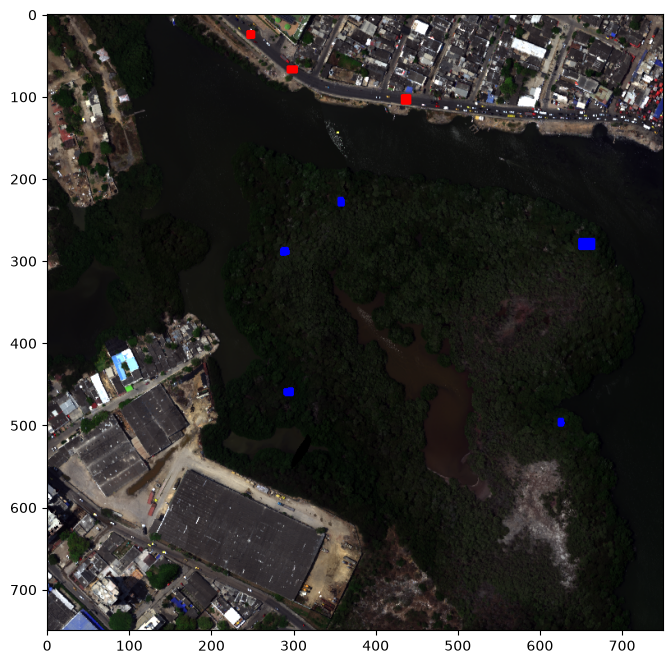

In [12]:
img_copy=imagen.copy()
for (x, y) in punt_si:
    cv2.circle(img_copy, (x, y), 1, (255, 0, 0), 2)
for (x, y) in punt_no:
    cv2.circle(img_copy, (x, y), 1, (0, 0, 255), 2)
plt.figure(figsize=(8, 8))
plt.imshow(img_copy)
plt.show()

Sacamos las firmas espectrales de cada punto y las dibujamos

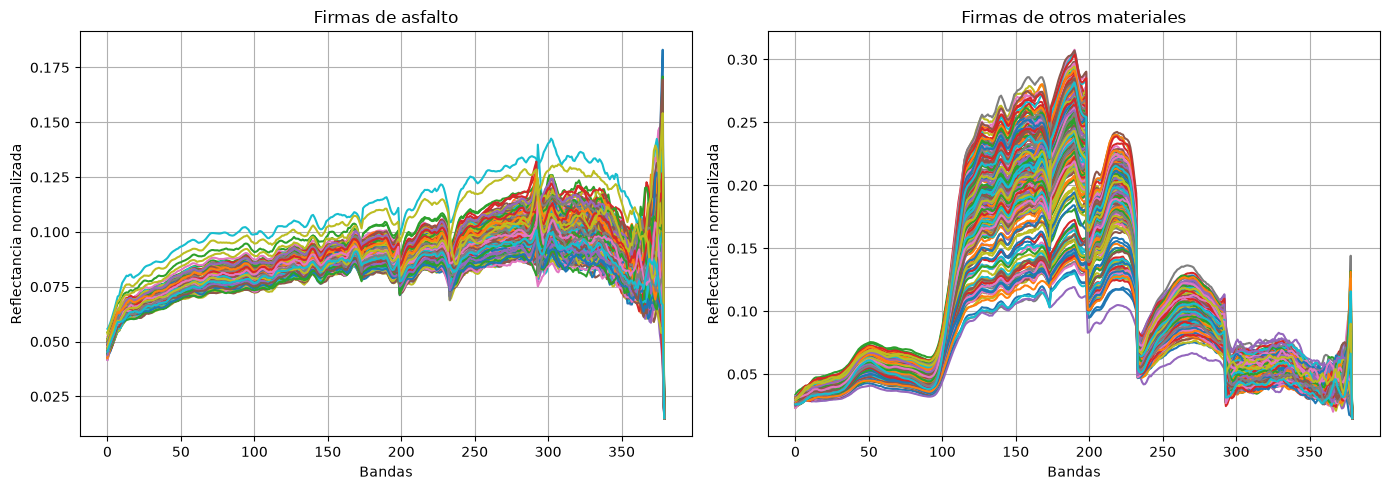

In [13]:
l_pix_si=[]
l_pix_no=[]
for pix in punt_si:
  l_pix_si.append(arr_norm[pix[1],pix[0],:])
for pix in punt_no:
  l_pix_no.append(arr_norm[pix[1],pix[0],:])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lista, titulo) in zip(axes, [(l_pix_si, "Firmas de asfalto"), (l_pix_no, "Firmas de otros materiales")]):
    for pix in lista:
        ax.plot(pix)
    ax.set_xlabel("Bandas")
    ax.set_ylabel("Reflectancia normalizada")
    ax.set_title(titulo)
    ax.grid(True)
plt.tight_layout()
plt.show()

Creamos el dataset (1 = asfalto, 0 = otro), lo desordenamos y lo partimos en entrenamiento y prueba

In [14]:
firmas=np.concatenate([l_pix_si, l_pix_no])
etiquetas=[1]*len(l_pix_si) + [0]*len(l_pix_no)
df=pd.DataFrame(firmas)
df['label']=etiquetas
df=df.sample(frac=1, random_state=42).reset_index(drop=True)

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df['label'],
    random_state=42
)
df_train.shape

(352, 381)

Calculamos el pixel promedio (mediana) del material y de los otros

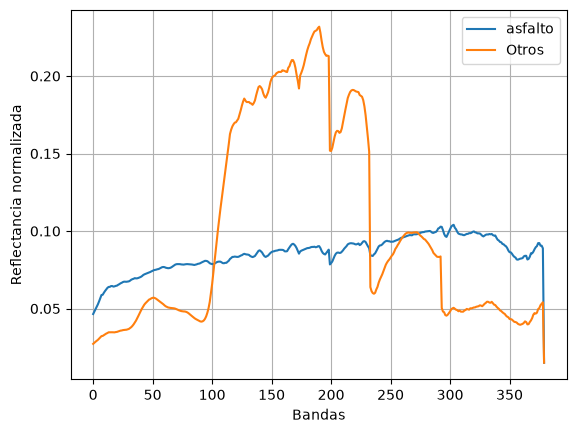

In [15]:
firm_si_train=df_train[df_train['label']==1].drop(columns='label').to_numpy()
firm_no_train=df_train[df_train['label']==0].drop(columns='label').to_numpy()
pix_prom_train=np.median(firm_si_train, axis=0)
pix_prom_no=np.median(firm_no_train, axis=0)
plt.plot(pix_prom_train, label="asfalto")
plt.plot(pix_prom_no, label="Otros")
plt.xlabel("Bandas")
plt.ylabel("Reflectancia normalizada")
plt.legend()
plt.grid()
plt.show()

Longitud de arco por tramos de 55 bandas, para ver en qué tramos se diferencian más

0 - 55  material: 0.0301  otros: 0.0314
55 - 110  material: 0.0133  otros: 0.0982
110 - 165  material: 0.0243  otros: 0.0985
165 - 220  material: 0.0468  otros: 0.1847
220 - 275  material: 0.0301  otros: 0.1724
275 - 330  material: 0.0337  otros: 0.0679


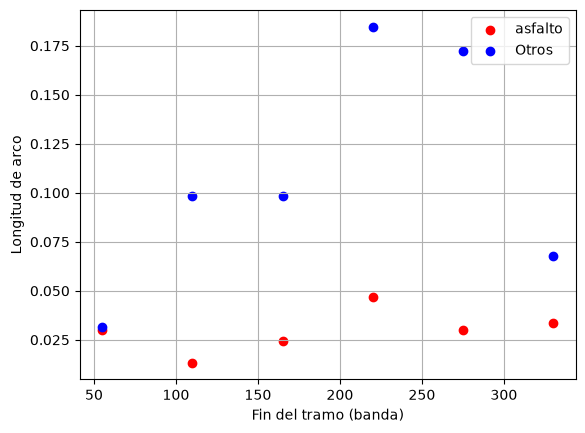

In [16]:
for i in range(55,381,55):
  s_si=long_arco(pix_prom_train[i-55:i])
  s_no=long_arco(pix_prom_no[i-55:i])
  plt.scatter(i, s_si, color="red")
  plt.scatter(i, s_no, color="blue")
  print(i-55,"-",i, " material:", round(s_si,4), " otros:", round(s_no,4))
plt.scatter([], [], color="red", label="asfalto")
plt.scatter([], [], color="blue", label="Otros")
plt.xlabel("Fin del tramo (banda)")
plt.ylabel("Longitud de arco")
plt.legend()
plt.grid()
plt.show()

Definimos los límites de los 2 tramos y la longitud de arco del pixel promedio

In [17]:
lim1=40
lim2=140
lim3=150
lim4=270
s1=long_arco(pix_prom_train[lim1:lim2])
s2=long_arco(pix_prom_train[lim3:lim4])
arr_s_prom=np.asarray([s1,s2])
print(arr_s_prom)

[0.03115562 0.08161523]


Probamos con las firmas del material para sacar el umbral (la similitud mínima, como en el original).
Antes quitamos las muestras atípicas: píxeles con ruido (brillos, olas, bordes) que quedan muy por debajo del resto.
Usamos la regla del diagrama de caja: es atípica si su similitud es menor que Q1 - 1.5·(Q3 - Q1). Si no hay ruido, no se quita nada.

Muestras atípicas quitadas: 6 de 152


/tmp/ipykernel_583352/3688515313.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(l_arc_si, vert=False)


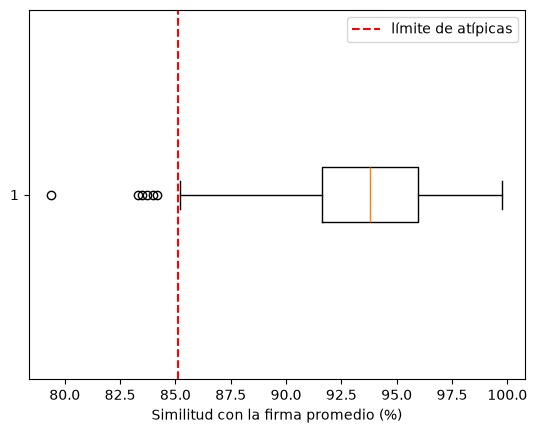

Min 85.21
Max 99.768


In [18]:
l_arc_si=[]
for id,row in df_train.iterrows():
  if(row['label']==1):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_si.append(sim)
q1,q3=np.percentile(l_arc_si,[25,75])
limite=q1-1.5*(q3-q1)
limpias=[s for s in l_arc_si if s>=limite]
print("Muestras atípicas quitadas:", len(l_arc_si)-len(limpias), "de", len(l_arc_si))
plt.boxplot(l_arc_si, vert=False)
plt.axvline(limite, color="red", linestyle="--", label="límite de atípicas")
plt.xlabel("Similitud con la firma promedio (%)")
plt.legend()
plt.show()
umbral=round(np.min(limpias),3)
print("Min", umbral)
print("Max", round(np.max(l_arc_si),3))

Probamos con las firmas de otros materiales

In [19]:
l_arc_no=[]
cont=0
for id,row in df_train.iterrows():
  if(row['label']==0):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_no.append(sim)
    if(sim<umbral):
      cont+=1
print("Otros bien separados:", cont, "de", len(l_arc_no))
print("Min", round(np.min(l_arc_no),3))
print("Max", round(np.max(l_arc_no),3))

Otros bien separados: 200 de 200
Min 24.194
Max 56.238


Probamos el método con el conjunto de prueba y calculamos las métricas

In [20]:
predicciones=[]
for id,row in df_test.iterrows():
  pix=np.asarray(row[0:380])
  long_arco1=long_arco(pix[lim1:lim2])
  long_arco2=long_arco(pix[lim3:lim4])
  arr_s_pix=np.asarray([long_arco1,long_arco2])
  sim=similitud_porcentual(arr_s_prom,arr_s_pix)
  if(sim>=umbral):
    predicciones.append(1)
  else:
    predicciones.append(0)
df_test['pred']=predicciones

y_true = df_test['label']
y_pred = df_test['pred']
print("Accuracy :", round(accuracy_score(y_true, y_pred),3))
print("Precision:", round(precision_score(y_true, y_pred),3))
print("Recall   :", round(recall_score(y_true, y_pred),3))
print("F1-score :", round(f1_score(y_true, y_pred),3))
print("\nMatriz de confusión:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.989
Precision: 1.0
Recall   : 0.974
F1-score : 0.987

Matriz de confusión:
[[50  0]
 [ 1 37]]


Desplegamos el método sobre la imagen. Guardamos la similitud de cada píxel en `mapa` para usarla al final

Porcentaje de asfalto: 4.158 %


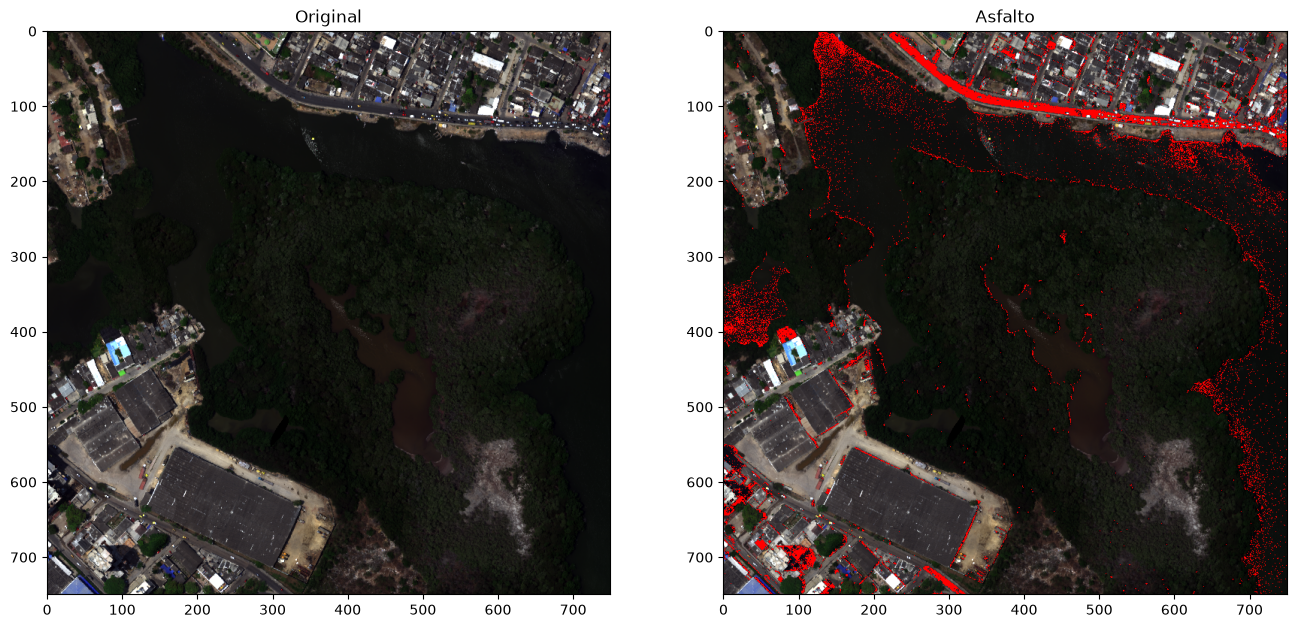

In [21]:
img_marcada=imagen.copy()
tam=arr_norm.shape
mapa=np.zeros((tam[0],tam[1]))
cont_pix=0
for i in range(tam[0]):
  for j in range(tam[1]):
    if(not con_datos[i][j]):
      continue
    #Obtenemos el pixel i,j de la imagen
    pix=arr_norm[i][j]
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    mapa[i][j]=sim
    if(sim>=umbral):
      img_marcada[i][j]=(255, 0, 0)
      cont_pix+=1
porc_pix_arc=(cont_pix/(tam[0]*tam[1]))*100
print("Porcentaje de asfalto:", round(porc_pix_arc,3),"%")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(imagen)
axes[0].set_title("Original")
axes[1].imshow(img_marcada)
axes[1].set_title("Asfalto")
plt.show()
plt.imsave("../resultados/cartagena3_asfalto.png", img_marcada)

#Guardamos lo de este material para la imagen final
mapas["asfalto"]=mapa
umbrales["asfalto"]=umbral

# Material 2: vegetacion

Sacamos los píxeles de los recuadros: vegetacion (si) y los demás materiales (no). Tomamos 250 de cada uno al azar, como en el original

In [22]:
df_si=pixeles_de(recuadros["vegetacion"])
df_no=pixeles_de(pd.concat([recuadros[m] for m in recuadros if m!="vegetacion"]))
print("Píxeles de vegetacion:", len(df_si), " otros:", len(df_no))
df_si=df_si.sample(n=min(250,len(df_si)),random_state=42)
df_no=df_no.sample(n=min(250,len(df_no)),random_state=42)
punt_si=df_si[["x","y"]].astype(int).to_numpy()
punt_no=df_no[["x","y"]].astype(int).to_numpy()
print("Usados:", len(punt_si), len(punt_no))

Píxeles de vegetacion: 381  otros: 190
Usados: 250 190


Dibujamos los puntos sobre la imagen (rojo = vegetacion, azul = otros)

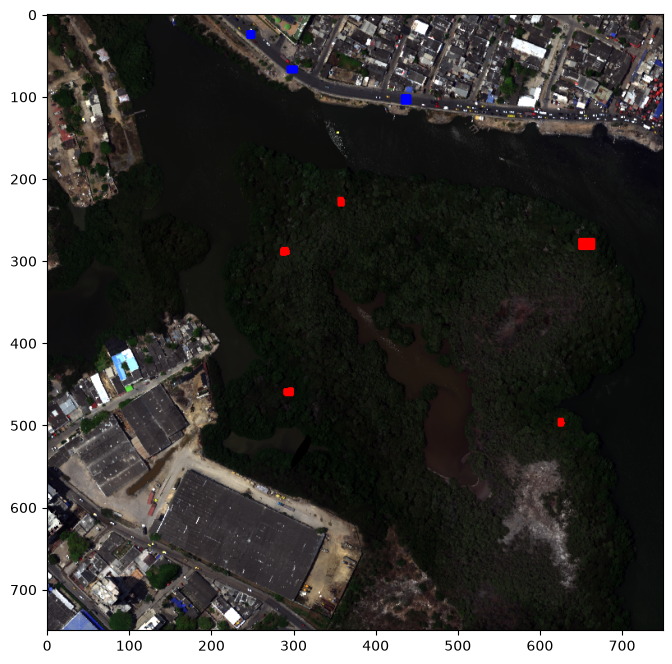

In [23]:
img_copy=imagen.copy()
for (x, y) in punt_si:
    cv2.circle(img_copy, (x, y), 1, (255, 0, 0), 2)
for (x, y) in punt_no:
    cv2.circle(img_copy, (x, y), 1, (0, 0, 255), 2)
plt.figure(figsize=(8, 8))
plt.imshow(img_copy)
plt.show()

Sacamos las firmas espectrales de cada punto y las dibujamos

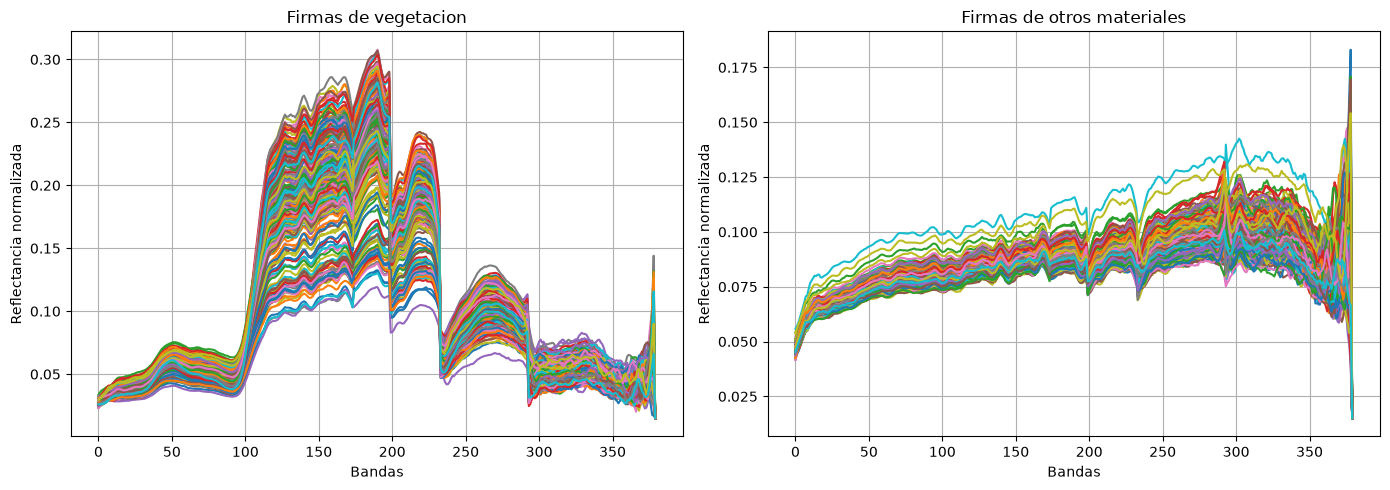

In [24]:
l_pix_si=[]
l_pix_no=[]
for pix in punt_si:
  l_pix_si.append(arr_norm[pix[1],pix[0],:])
for pix in punt_no:
  l_pix_no.append(arr_norm[pix[1],pix[0],:])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (lista, titulo) in zip(axes, [(l_pix_si, "Firmas de vegetacion"), (l_pix_no, "Firmas de otros materiales")]):
    for pix in lista:
        ax.plot(pix)
    ax.set_xlabel("Bandas")
    ax.set_ylabel("Reflectancia normalizada")
    ax.set_title(titulo)
    ax.grid(True)
plt.tight_layout()
plt.show()

Creamos el dataset (1 = vegetacion, 0 = otro), lo desordenamos y lo partimos en entrenamiento y prueba

In [25]:
firmas=np.concatenate([l_pix_si, l_pix_no])
etiquetas=[1]*len(l_pix_si) + [0]*len(l_pix_no)
df=pd.DataFrame(firmas)
df['label']=etiquetas
df=df.sample(frac=1, random_state=42).reset_index(drop=True)

df_train, df_test = train_test_split(
    df,
    test_size=0.20,
    stratify=df['label'],
    random_state=42
)
df_train.shape

(352, 381)

Calculamos el pixel promedio (mediana) del material y de los otros

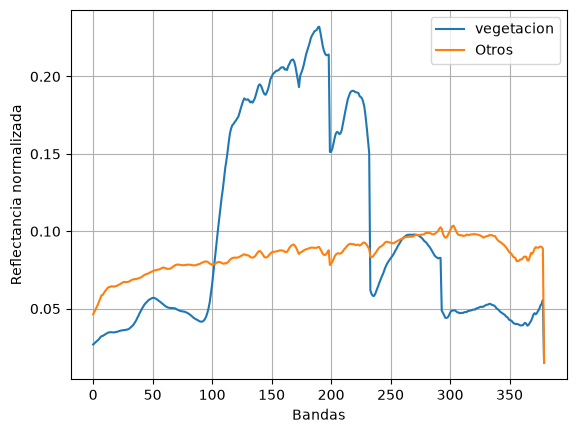

In [26]:
firm_si_train=df_train[df_train['label']==1].drop(columns='label').to_numpy()
firm_no_train=df_train[df_train['label']==0].drop(columns='label').to_numpy()
pix_prom_train=np.median(firm_si_train, axis=0)
pix_prom_no=np.median(firm_no_train, axis=0)
plt.plot(pix_prom_train, label="vegetacion")
plt.plot(pix_prom_no, label="Otros")
plt.xlabel("Bandas")
plt.ylabel("Reflectancia normalizada")
plt.legend()
plt.grid()
plt.show()

Longitud de arco por tramos de 55 bandas, para ver en qué tramos se diferencian más

0 - 55  material: 0.0318  otros: 0.0297
55 - 110  material: 0.0994  otros: 0.0137
110 - 165  material: 0.097  otros: 0.0251
165 - 220  material: 0.1842  otros: 0.0456
220 - 275  material: 0.173  otros: 0.0294
275 - 330  material: 0.0653  otros: 0.033


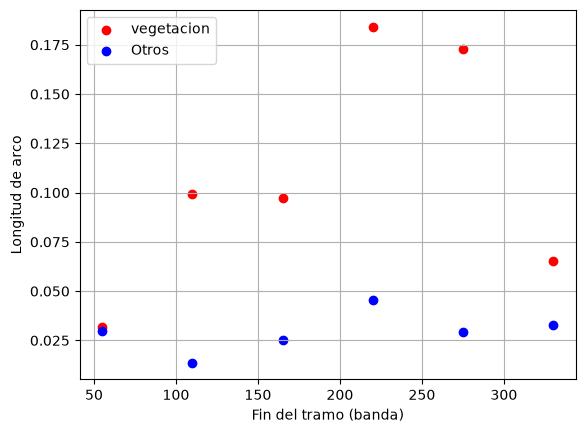

In [27]:
for i in range(55,381,55):
  s_si=long_arco(pix_prom_train[i-55:i])
  s_no=long_arco(pix_prom_no[i-55:i])
  plt.scatter(i, s_si, color="red")
  plt.scatter(i, s_no, color="blue")
  print(i-55,"-",i, " material:", round(s_si,4), " otros:", round(s_no,4))
plt.scatter([], [], color="red", label="vegetacion")
plt.scatter([], [], color="blue", label="Otros")
plt.xlabel("Fin del tramo (banda)")
plt.ylabel("Longitud de arco")
plt.legend()
plt.grid()
plt.show()

Definimos los límites de los 2 tramos y la longitud de arco del pixel promedio

In [28]:
lim1=40
lim2=140
lim3=150
lim4=270
s1=long_arco(pix_prom_train[lim1:lim2])
s2=long_arco(pix_prom_train[lim3:lim4])
arr_s_prom=np.asarray([s1,s2])
print(arr_s_prom)

[0.18394616 0.36861467]


Probamos con las firmas del material para sacar el umbral (la similitud mínima, como en el original).
Antes quitamos las muestras atípicas: píxeles con ruido (brillos, olas, bordes) que quedan muy por debajo del resto.
Usamos la regla del diagrama de caja: es atípica si su similitud es menor que Q1 - 1.5·(Q3 - Q1). Si no hay ruido, no se quita nada.

Muestras atípicas quitadas: 10 de 200


/tmp/ipykernel_583352/3688515313.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(l_arc_si, vert=False)


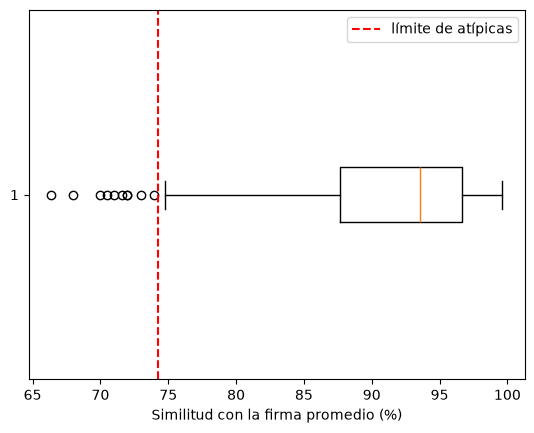

Min 74.736
Max 99.614


In [29]:
l_arc_si=[]
for id,row in df_train.iterrows():
  if(row['label']==1):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_si.append(sim)
q1,q3=np.percentile(l_arc_si,[25,75])
limite=q1-1.5*(q3-q1)
limpias=[s for s in l_arc_si if s>=limite]
print("Muestras atípicas quitadas:", len(l_arc_si)-len(limpias), "de", len(l_arc_si))
plt.boxplot(l_arc_si, vert=False)
plt.axvline(limite, color="red", linestyle="--", label="límite de atípicas")
plt.xlabel("Similitud con la firma promedio (%)")
plt.legend()
plt.show()
umbral=round(np.min(limpias),3)
print("Min", umbral)
print("Max", round(np.max(l_arc_si),3))

Probamos con las firmas de otros materiales

In [30]:
l_arc_no=[]
cont=0
for id,row in df_train.iterrows():
  if(row['label']==0):
    pix=np.asarray(row[0:380])
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    l_arc_no.append(sim)
    if(sim<umbral):
      cont+=1
print("Otros bien separados:", cont, "de", len(l_arc_no))
print("Min", round(np.min(l_arc_no),3))
print("Max", round(np.max(l_arc_no),3))

Otros bien separados: 152 de 152
Min 29.722
Max 45.722


Probamos el método con el conjunto de prueba y calculamos las métricas

In [31]:
predicciones=[]
for id,row in df_test.iterrows():
  pix=np.asarray(row[0:380])
  long_arco1=long_arco(pix[lim1:lim2])
  long_arco2=long_arco(pix[lim3:lim4])
  arr_s_pix=np.asarray([long_arco1,long_arco2])
  sim=similitud_porcentual(arr_s_prom,arr_s_pix)
  if(sim>=umbral):
    predicciones.append(1)
  else:
    predicciones.append(0)
df_test['pred']=predicciones

y_true = df_test['label']
y_pred = df_test['pred']
print("Accuracy :", round(accuracy_score(y_true, y_pred),3))
print("Precision:", round(precision_score(y_true, y_pred),3))
print("Recall   :", round(recall_score(y_true, y_pred),3))
print("F1-score :", round(f1_score(y_true, y_pred),3))
print("\nMatriz de confusión:")
print(confusion_matrix(y_true, y_pred))

Accuracy : 0.977
Precision: 1.0


Recall   : 0.96
F1-score : 0.98

Matriz de confusión:
[[38  0]
 [ 2 48]]


Desplegamos el método sobre la imagen. Guardamos la similitud de cada píxel en `mapa` para usarla al final

Porcentaje de vegetacion: 51.297 %


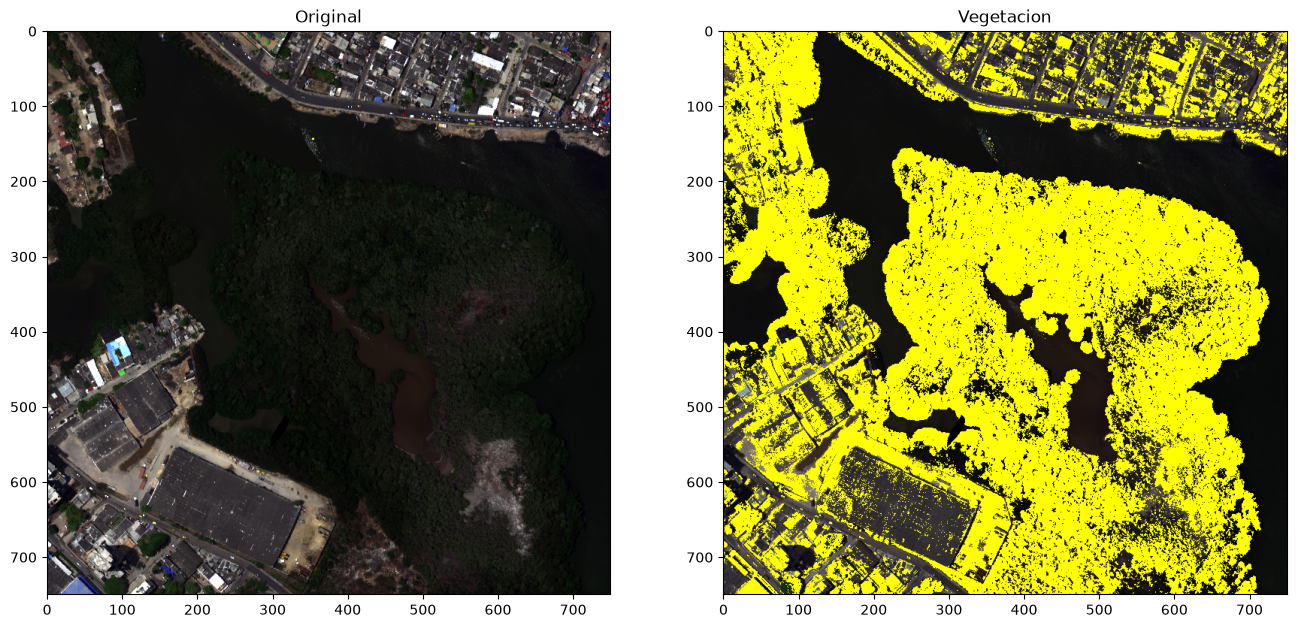

In [32]:
img_marcada=imagen.copy()
tam=arr_norm.shape
mapa=np.zeros((tam[0],tam[1]))
cont_pix=0
for i in range(tam[0]):
  for j in range(tam[1]):
    if(not con_datos[i][j]):
      continue
    #Obtenemos el pixel i,j de la imagen
    pix=arr_norm[i][j]
    long_arco1=long_arco(pix[lim1:lim2])
    long_arco2=long_arco(pix[lim3:lim4])
    arr_s_pix=np.asarray([long_arco1,long_arco2])
    sim=similitud_porcentual(arr_s_prom,arr_s_pix)
    mapa[i][j]=sim
    if(sim>=umbral):
      img_marcada[i][j]=(255, 255, 0)
      cont_pix+=1
porc_pix_arc=(cont_pix/(tam[0]*tam[1]))*100
print("Porcentaje de vegetacion:", round(porc_pix_arc,3),"%")

fig, axes = plt.subplots(1, 2, figsize=(16, 8))
axes[0].imshow(imagen)
axes[0].set_title("Original")
axes[1].imshow(img_marcada)
axes[1].set_title("Vegetacion")
plt.show()
plt.imsave("../resultados/cartagena3_vegetacion.png", img_marcada)

#Guardamos lo de este material para la imagen final
mapas["vegetacion"]=mapa
umbrales["vegetacion"]=umbral

# Imagen final con todos los materiales

Si un píxel pasa el umbral de varios materiales, gana el más parecido (el de mayor % de similitud)

asfalto : 4.158 %
vegetacion : 51.297 %


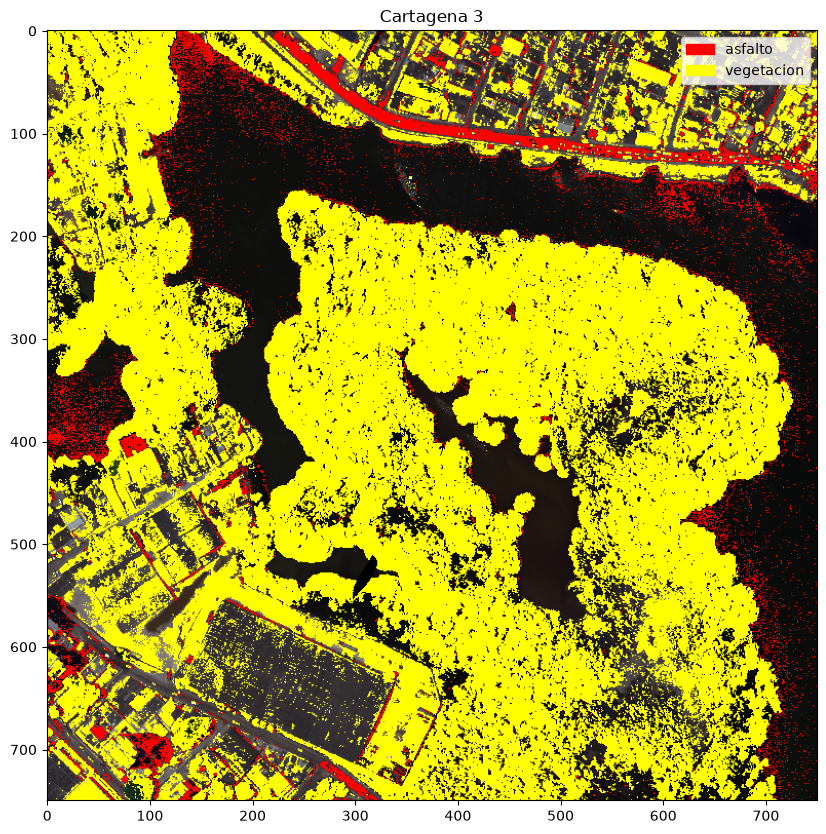

In [33]:
colores={"asfalto":(255, 0, 0), "vegetacion":(255, 255, 0)}
img_final=imagen.copy()
mejor_sim=np.zeros(con_datos.shape)
ganador=np.full(con_datos.shape, "", dtype=object)
for nombre in mapas:
  pasa=(mapas[nombre]>=umbrales[nombre]) & (mapas[nombre]>mejor_sim)
  mejor_sim[pasa]=mapas[nombre][pasa]
  ganador[pasa]=nombre
for nombre in mapas:
  img_final[ganador==nombre]=colores[nombre]
  print(nombre, ":", round(np.mean(ganador==nombre)*100,3), "%")

plt.figure(figsize=(10, 10))
plt.imshow(img_final)
plt.legend(handles=[mpatches.Patch(color=np.array(colores[m])/255, label=m.replace("_"," ")) for m in colores], loc="upper right")
plt.title("Cartagena 3")
plt.show()
plt.imsave("../resultados/cartagena3_materiales_final.png", img_final)